In [1]:
%pylab inline
import os
import gc
import matplotlib
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTab
import massmap_utilities as mutilities
from configparser import ConfigParser
from pixel3D import cartesianGrid3D
from scipy.stats import norm as statnorm
import matplotlib as mpl
import sim_analysis_utilities as utilities

Populating the interactive namespace from numpy and matplotlib


In [2]:
configName  =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/config-nl1.ini'
parser      =   ConfigParser()
parser.read(configName)
outDir      =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/densityMap/'
inDir       =   '/home/xiangchong/work/gw_ipmu/work/massMapSparse/s19/reGaus_catalog/'
inDir2      =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/'

In [3]:
# Number map
extList={}
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir2,'%s_no_m.fits'%fieldname )
    data=pyfits.getdata(infname)
    ra,dec=utilities.get_radec(data)
    if fieldname=='VVDS':
        addR=(ra<300.).astype(int)*360
        ra+=addR
    #head=pyfits.getheader(infname,ext=1)
    raMin=(np.min(ra)-.1)*60.
    raMax=(np.max(ra)+.1)*60.
    decMin=(np.min(dec)-.1)*60.
    decMax=(np.max(dec)+.1)*60.
    ext=(raMin/60.,raMax/60.,decMin/60.,decMax/60.)
    extList.update({fieldname:ext})
    nx=int((raMax-raMin+1)//2*2)
    ny=int((decMax-decMin+1)//2*2)
    print(nx,ny)
    parser.set('transPlane','xmin','%s'%raMin)
    parser.set('transPlane','ymin','%s'%decMin)
    parser.set('transPlane','nx','%d'%nx)
    parser.set('transPlane','ny','%d'%ny)
    gridInfo    =   cartesianGrid3D(parser)
    x,y,z=ra,dec,data['dnnz_photoz_best']
    v=utilities.get_psf_size(data)
    out=gridInfo.pixelize_data(x,y,z,v,ws=None)
    pyfits.writeto(os.path.join(outDir,'%s_fwhmMap.fits' %fieldname),out,overwrite=True)
    del data
    gc.collect()

632 324
1508 408
2752 394
1188 194
1976 422
2270 144


XMM
(1, 324, 632)
VVDS
(1, 422, 1976)
GAMA09H
(1, 408, 1508)
GAMA15H
(1, 194, 1188)
WIDE12H
(1, 394, 2752)
HECTOMAP
(1, 144, 2270)


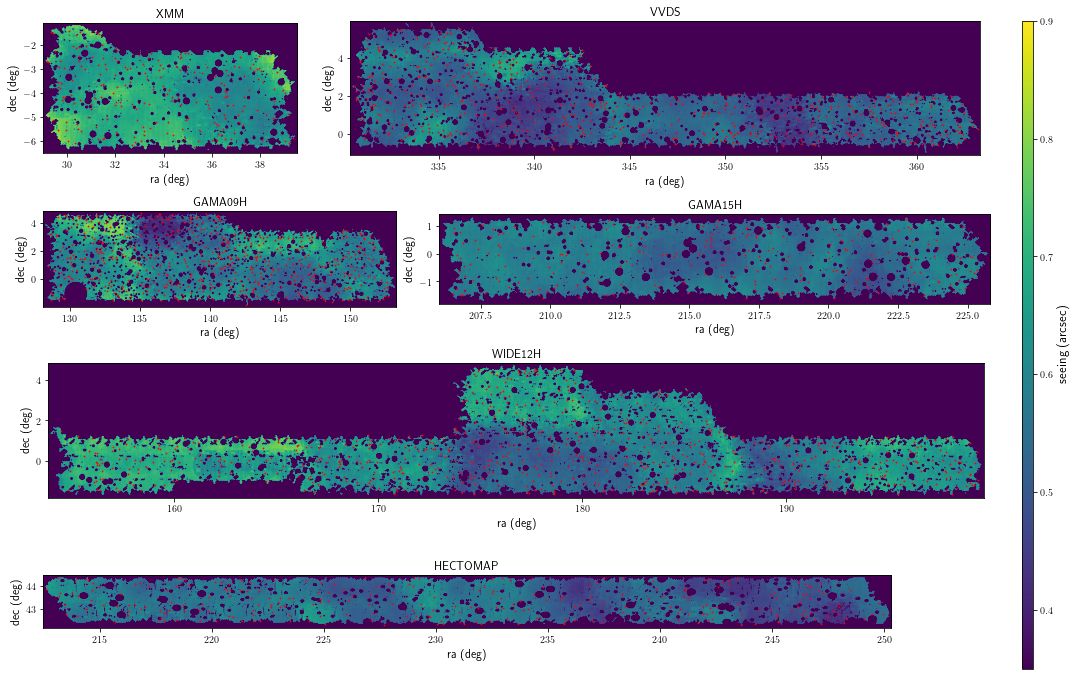

In [8]:
pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
lenList={}
imgList={}
cmax=0.
for fieldname in pltList:
    data=pyfits.getdata(os.path.join(outDir,'%s_fwhmMap.fits' %fieldname))
    print(fieldname)
    print(data.shape)
    lenList.update({fieldname:data.shape})
    imgList.update({fieldname:data})
    fmax=np.max(data)
    if fmax>cmax:
        cmax=fmax

psfs=astTab.Table.read('wrkDir/s19/s19-1/info_newS19Mask_fd001_sim.csv')
ra=psfs['psf_ra']
dec=psfs['psf_dec']

configName  =   'wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/char.ini'
parser2      =   ConfigParser()
parser2.read(configName)
plt.close()
#norm = mpl.colors.SymLogNorm(linthresh=0.4,vmin=5, vmax=cmax)
norm=mpl.colors.Normalize(vmin=0.35, vmax=0.90)

fig = plt.figure(figsize=(15,10))
ratio=int(1./(lenList['VVDS'][-1]/lenList['VVDS'][-2]/lenList['XMM'][-1]*lenList['XMM'][-2]+1.)*10.+0.5)
ax1 = plt.subplot2grid((8, 10), (0, 0), colspan=ratio,rowspan=2)
ax1.set_title('XMM',fontsize=12)
msk=psfs['field']=='XMM'
ax1.scatter(ra[msk],dec[msk],s=.6,c='red')
ax1.imshow(imgList['XMM'][0],origin='lower',extent=extList['XMM'],norm=norm)
ax1.set_xlabel('ra (deg)',fontsize=12)
ax1.set_ylabel('dec (deg)',fontsize=12)
ax2 = plt.subplot2grid((8, 10), (0, ratio), colspan=10-ratio,rowspan=2)
ax2.set_title('VVDS',fontsize=12)
msk=psfs['field']=='VVDS'
addR=(ra<300.).astype(int)*360
ax2.scatter(ra[msk]+addR[msk],dec[msk],s=.6,c='red')
ax2.imshow(imgList['VVDS'][0],origin='lower',extent=extList['VVDS'],norm=norm)
ax2.set_xlabel('ra (deg)',fontsize=12)
ax2.set_ylabel('dec (deg)',fontsize=12)

ratio=int(1./(lenList['GAMA15H'][-1]/lenList['GAMA15H'][-2]/lenList['GAMA09H'][-1]*lenList['GAMA09H'][-2]+1.)*10.+0.5)
ax3 = plt.subplot2grid((8, 10), (2, 0), colspan=ratio,rowspan=2)
ax3.set_title('GAMA09H',fontsize=12)
msk=psfs['field']=='GAMA09H'
ax3.scatter(ra[msk],dec[msk],s=.6,c='red')
ax3.imshow(imgList['GAMA09H'][0],origin='lower',extent=extList['GAMA09H'],norm=norm)
ax3.set_xlabel('ra (deg)',fontsize=12)
ax3.set_ylabel('dec (deg)',fontsize=12)
ax4 = plt.subplot2grid((8, 10), (2, ratio), colspan=10-ratio,rowspan=2)
ax4.set_title('GAMA15H',fontsize=12)
msk=psfs['field']=='GAMA15H'
ax4.scatter(ra[msk],dec[msk],s=.6,c='red')
ax4.imshow(imgList['GAMA15H'][0],origin='lower',extent=extList['GAMA15H'],norm=norm)
ax4.set_xlabel('ra (deg)',fontsize=12)
ax4.set_ylabel('dec (deg)',fontsize=12)

ax5 = plt.subplot2grid((8, 10), (4, 0), colspan=10,rowspan=2)
ax5.set_title('WIDE12H',fontsize=12)
msk=psfs['field']=='WIDE12H'
ax5.scatter(ra[msk],dec[msk],s=.6,c='red')
ax5.imshow(imgList['WIDE12H'][0],origin='lower',extent=extList['WIDE12H'],norm=norm)
ax5.set_xlabel('ra (deg)',fontsize=12)
ax5.set_ylabel('dec (deg)',fontsize=12)

ax6 = plt.subplot2grid((8, 10), (6, 0), colspan=9,rowspan=2)
ax6.set_title('HECTOMAP',fontsize=12)
msk=psfs['field']=='HECTOMAP'
ax6.scatter(ra[msk],dec[msk],s=.6,c='red')
mm=ax6.imshow(imgList['HECTOMAP'][0],origin='lower',extent=extList['HECTOMAP'],norm=norm)
ax6.set_xlabel('ra (deg)',fontsize=12)
ax6.set_ylabel('dec (deg)',fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.05, right=0.92, top=0.95)
cax = plt.axes([0.95, 0.05, 0.01, 0.9])
plt.colorbar(mm,aspect=10,cax=cax)

cax.set_ylabel('seeing (arcsec)',fontsize=13)
fig.savefig(os.path.join(outDir,'fwhmMap.eps'))
fig.savefig(os.path.join(outDir,'fwhmMap.png'))

In [12]:
# Number map
extList={}
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir2,'%s_no_m.fits'%fieldname )
    data=pyfits.getdata(infname)
    ra,dec=utilities.get_radec(data)
    if fieldname=='VVDS':
        addR=(ra<300.).astype(int)*360
        ra+=addR
    #head=pyfits.getheader(infname,ext=1)
    raMin=(np.min(ra)-.1)*60.
    raMax=(np.max(ra)+.1)*60.
    decMin=(np.min(dec)-.1)*60.
    decMax=(np.max(dec)+.1)*60.
    ext=(raMin/60.,raMax/60.,decMin/60.,decMax/60.)
    extList.update({fieldname:ext})
    nx=int((raMax-raMin+1)//2*2)
    ny=int((decMax-decMin+1)//2*2)
    print(nx,ny)
    parser.set('transPlane','xmin','%s'%raMin)
    parser.set('transPlane','ymin','%s'%decMin)
    parser.set('transPlane','nx','%d'%nx)
    parser.set('transPlane','ny','%d'%ny)
    gridInfo    =   cartesianGrid3D(parser)
    x,y,z=ra,dec,data['dnnz_photoz_best']
    v=data['i_inputcount_value']
    out=gridInfo.pixelize_data(x,y,z,v,ws=None)
    pyfits.writeto(os.path.join(outDir,'%s_icountInMap.fits' %fieldname),out,overwrite=True)
    del data
    gc.collect()

632 324
1508 408
2752 394
1188 194
1976 422
2270 144


In [27]:
gridInfo.sigma

-0.016666666666666666

XMM
(1, 324, 632)
VVDS
(1, 422, 1976)
GAMA09H
(1, 408, 1508)
GAMA15H
(1, 194, 1188)
WIDE12H
(1, 394, 2752)
HECTOMAP
(1, 144, 2270)


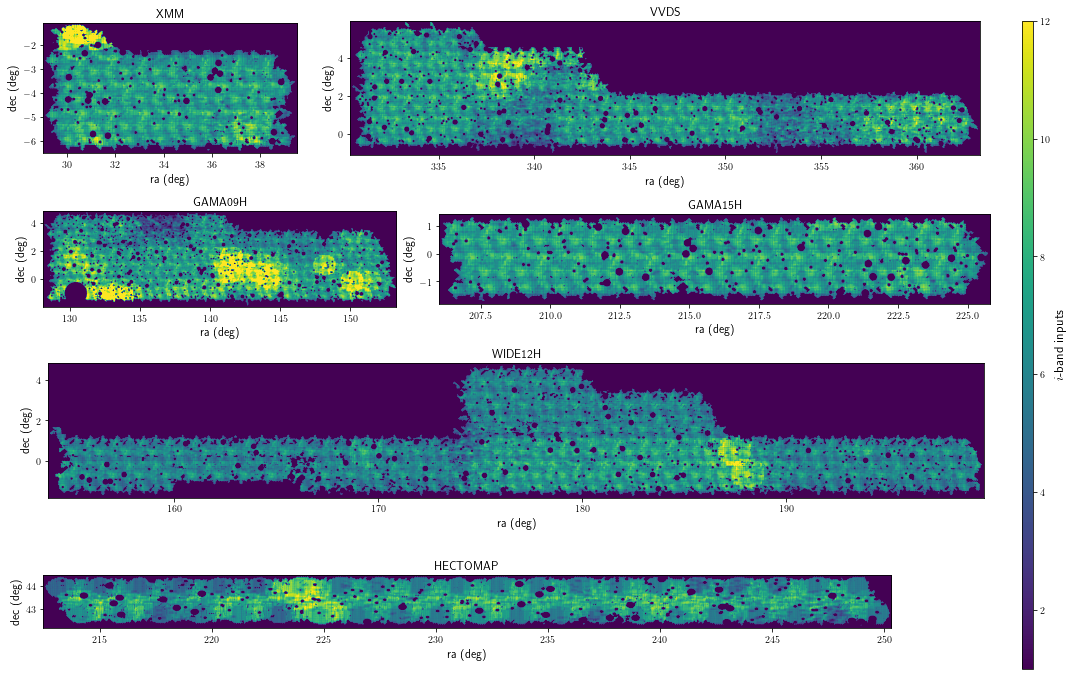

In [13]:
pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
lenList={}
imgList={}
cmax=0.
for fieldname in pltList:
    data=pyfits.getdata(os.path.join(outDir,'%s_icountInMap.fits' %fieldname))
    print(fieldname)
    print(data.shape)
    lenList.update({fieldname:data.shape})
    imgList.update({fieldname:data})
    fmax=np.max(data)
    if fmax>cmax:
        cmax=fmax

configName  =   'wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/char.ini'
parser2      =   ConfigParser()
parser2.read(configName)
plt.close()
#norm = mpl.colors.SymLogNorm(linthresh=0.4,vmin=5, vmax=cmax)
norm=mpl.colors.Normalize(vmin=1, vmax=12)

fig = plt.figure(figsize=(15,10))
ratio=int(1./(lenList['VVDS'][-1]/lenList['VVDS'][-2]/lenList['XMM'][-1]*lenList['XMM'][-2]+1.)*10.+0.5)
ax1 = plt.subplot2grid((8, 10), (0, 0), colspan=ratio,rowspan=2)
ax1.set_title('XMM',fontsize=12)
ax1.imshow(imgList['XMM'][0],origin='lower',extent=extList['XMM'],norm=norm)
ax1.set_xlabel('ra (deg)',fontsize=12)
ax1.set_ylabel('dec (deg)',fontsize=12)
ax2 = plt.subplot2grid((8, 10), (0, ratio), colspan=10-ratio,rowspan=2)
ax2.set_title('VVDS',fontsize=12)
ax2.imshow(imgList['VVDS'][0],origin='lower',extent=extList['VVDS'],norm=norm)
ax2.set_xlabel('ra (deg)',fontsize=12)
ax2.set_ylabel('dec (deg)',fontsize=12)

ratio=int(1./(lenList['GAMA15H'][-1]/lenList['GAMA15H'][-2]/lenList['GAMA09H'][-1]*lenList['GAMA09H'][-2]+1.)*10.+0.5)
ax3 = plt.subplot2grid((8, 10), (2, 0), colspan=ratio,rowspan=2)
ax3.set_title('GAMA09H',fontsize=12)
ax3.imshow(imgList['GAMA09H'][0],origin='lower',extent=extList['GAMA09H'],norm=norm)
ax3.set_xlabel('ra (deg)',fontsize=12)
ax3.set_ylabel('dec (deg)',fontsize=12)
ax4 = plt.subplot2grid((8, 10), (2, ratio), colspan=10-ratio,rowspan=2)
ax4.set_title('GAMA15H',fontsize=12)
ax4.imshow(imgList['GAMA15H'][0],origin='lower',extent=extList['GAMA15H'],norm=norm)
ax4.set_xlabel('ra (deg)',fontsize=12)
ax4.set_ylabel('dec (deg)',fontsize=12)

ax5 = plt.subplot2grid((8, 10), (4, 0), colspan=10,rowspan=2)
ax5.set_title('WIDE12H',fontsize=12)
ax5.imshow(imgList['WIDE12H'][0],origin='lower',extent=extList['WIDE12H'],norm=norm)
ax5.set_xlabel('ra (deg)',fontsize=12)
ax5.set_ylabel('dec (deg)',fontsize=12)

ax6 = plt.subplot2grid((8, 10), (6, 0), colspan=9,rowspan=2)
ax6.set_title('HECTOMAP',fontsize=12)
mm=ax6.imshow(imgList['HECTOMAP'][0],origin='lower',extent=extList['HECTOMAP'],norm=norm)
ax6.set_xlabel('ra (deg)',fontsize=12)
ax6.set_ylabel('dec (deg)',fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.05, right=0.92, top=0.95)
cax = plt.axes([0.95, 0.05, 0.01, 0.9])
plt.colorbar(mm,aspect=10,cax=cax)

cax.set_ylabel(r'$i$-band inputs',fontsize=13)
fig.savefig(os.path.join(outDir,'icountInMap.eps'))
fig.savefig(os.path.join(outDir,'icountInMap.png'))

In [22]:
# Number map
extList={}
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir,'%s.fits'%fieldname )
    data=pyfits.getdata(infname)
    aveWeight=np.average(data['weight'])
    if fieldname=='VVDS':
        addR=(data['ra']<300.).astype(int)*360
        data['ra']+=addR
    #head=pyfits.getheader(infname,ext=1)
    raMin=(np.min(data['ra'])-.1)*60.
    raMax=(np.max(data['ra'])+.1)*60.
    decMin=(np.min(data['dec'])-.1)*60.
    decMax=(np.max(data['dec'])+.1)*60.
    ext=(raMin/60.,raMax/60.,decMin/60.,decMax/60.)
    extList.update({fieldname:ext})
    if False:
        continue
    nx=int((raMax-raMin+1)//2*2)
    ny=int((decMax-decMin+1)//2*2)
    print(nx,ny)
    parser.set('transPlane','xmin','%s'%raMin)
    parser.set('transPlane','ymin','%s'%decMin)
    parser.set('transPlane','nx','%d'%nx)
    parser.set('transPlane','ny','%d'%ny)
    gridInfo    =   cartesianGrid3D(parser)
    x,y,z=data['ra'],data['dec'],data['dnn_zbest']
    ws=data['weight']
    # w*g1,w*g2,w for each pixel
    weightOutTmp=numpy.histogramdd((z,y,x),bins=(gridInfo.zbound,gridInfo.ybound,gridInfo.xbound))[0]
    mask0=weightOutTmp>0. # the mask before smoothing
    assert weightOutTmp.shape==gridInfo.shape,'the output shape is different from expectation?'
    # variance
    sigma2=np.zeros(gridInfo.shape)
    sigma2[mask0]=1./weightOutTmp[mask0]
    if gridInfo.sigma>0:
        # Gaussian Kernel in Fourier space (normalized in configuration space)
        gausKer=haloSim.GausAtom(ny=ny,nx=nx,sigma=gridInfo.sigma/gridInfo.delta,fou=True,lnorm=2.)
        norm=gausKer[0,0]
        gausKer/=norm
        # smothing with Gausian Kernel
        weightOut=np.fft.ifft2(np.fft.fft2(weightOutTmp)*gausKer).real
    else:
        weightOut=weightOutTmp
    pyfits.writeto(os.path.join(outDir,'%s_numMap.fits' %fieldname),weightOut,overwrite=True)
    del weightOut
    gc.collect()

632 324
1508 408
2752 394
1188 194
1976 422
2270 144


XMM
(1, 324, 632)
VVDS
(1, 422, 1976)
GAMA09H
(1, 408, 1508)
GAMA15H
(1, 194, 1188)
WIDE12H
(1, 394, 2752)
HECTOMAP
(1, 144, 2270)


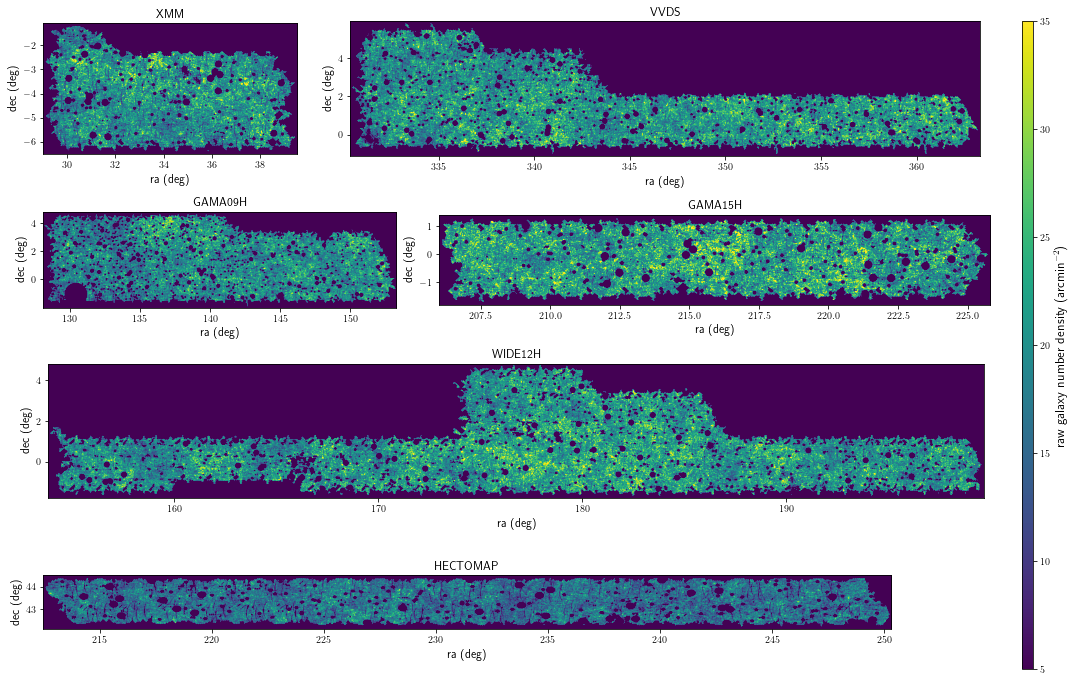

In [23]:
pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
lenList={}
imgList={}
cmax=0.
for fieldname in pltList:
    data=pyfits.getdata(os.path.join(outDir,'%s_numMap.fits' %fieldname))
    print(fieldname)
    print(data.shape)
    lenList.update({fieldname:data.shape})
    imgList.update({fieldname:data})
    fmax=np.max(data)
    if fmax>cmax:
        cmax=fmax
plt.close()
#norm = mpl.colors.SymLogNorm(linthresh=0.4,vmin=5, vmax=cmax)
norm=mpl.colors.Normalize(vmin=5, vmax=35)

fig = plt.figure(figsize=(15,10))
ratio=int(1./(lenList['VVDS'][-1]/lenList['VVDS'][-2]/lenList['XMM'][-1]*lenList['XMM'][-2]+1.)*10.+0.5)
ax1 = plt.subplot2grid((8, 10), (0, 0), colspan=ratio,rowspan=2)
ax1.set_title('XMM',fontsize=12)
ax1.imshow(imgList['XMM'][0],origin='lower',extent=extList['XMM'],norm=norm)
ax1.set_xlabel('ra (deg)',fontsize=12)
ax1.set_ylabel('dec (deg)',fontsize=12)
ax2 = plt.subplot2grid((8, 10), (0, ratio), colspan=10-ratio,rowspan=2)
ax2.set_title('VVDS',fontsize=12)
msk=psfs['field']=='VVDS'
ax2.imshow(imgList['VVDS'][0],origin='lower',extent=extList['VVDS'],norm=norm)
ax2.set_xlabel('ra (deg)',fontsize=12)
ax2.set_ylabel('dec (deg)',fontsize=12)

ratio=int(1./(lenList['GAMA15H'][-1]/lenList['GAMA15H'][-2]/lenList['GAMA09H'][-1]*lenList['GAMA09H'][-2]+1.)*10.+0.5)
ax3 = plt.subplot2grid((8, 10), (2, 0), colspan=ratio,rowspan=2)
ax3.set_title('GAMA09H',fontsize=12)
ax3.imshow(imgList['GAMA09H'][0],origin='lower',extent=extList['GAMA09H'],norm=norm)
ax3.set_xlabel('ra (deg)',fontsize=12)
ax3.set_ylabel('dec (deg)',fontsize=12)
ax4 = plt.subplot2grid((8, 10), (2, ratio), colspan=10-ratio,rowspan=2)
ax4.set_title('GAMA15H',fontsize=12)
ax4.imshow(imgList['GAMA15H'][0],origin='lower',extent=extList['GAMA15H'],norm=norm)
ax4.set_xlabel('ra (deg)',fontsize=12)
ax4.set_ylabel('dec (deg)',fontsize=12)

ax5 = plt.subplot2grid((8, 10), (4, 0), colspan=10,rowspan=2)
ax5.set_title('WIDE12H',fontsize=12)
ax5.imshow(imgList['WIDE12H'][0],origin='lower',extent=extList['WIDE12H'],norm=norm)
ax5.set_xlabel('ra (deg)',fontsize=12)
ax5.set_ylabel('dec (deg)',fontsize=12)

ax6 = plt.subplot2grid((8, 10), (6, 0), colspan=9,rowspan=2)
ax6.set_title('HECTOMAP',fontsize=12)
mm=ax6.imshow(imgList['HECTOMAP'][0],origin='lower',extent=extList['HECTOMAP'],norm=norm)
ax6.set_xlabel('ra (deg)',fontsize=12)
ax6.set_ylabel('dec (deg)',fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.05, right=0.92, top=0.95)
cax = plt.axes([0.95, 0.05, 0.01, 0.9])
plt.colorbar(mm,cax=cax)

cax.set_ylabel(r'raw galaxy number density (arcmin$^{-2}$)',fontsize=13)
fig.savefig(os.path.join(outDir,'densityMap.eps'))
fig.savefig(os.path.join(outDir,'densityMap.png'))

In [65]:
# Number map
extList={}
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir,'%s.fits'%fieldname )
    data=pyfits.getdata(infname)
    aveWeight=np.average(data['weight'])
    if fieldname=='VVDS':
        addR=(data['ra']<300.).astype(int)*360
        data['ra']+=addR
    #head=pyfits.getheader(infname,ext=1)
    raMin=(np.min(data['ra'])-.1)*60.
    raMax=(np.max(data['ra'])+.1)*60.
    decMin=(np.min(data['dec'])-.1)*60.
    decMax=(np.max(data['dec'])+.1)*60.
    ext=(raMin/60.,raMax/60.,decMin/60.,decMax/60.)
    extList.update({fieldname:ext})
    if False:
        continue
    nx=int((raMax-raMin+1)//2*2)
    ny=int((decMax-decMin+1)//2*2)
    print(nx,ny)
    parser.set('transPlane','xmin','%s'%raMin)
    parser.set('transPlane','ymin','%s'%decMin)
    parser.set('transPlane','nx','%d'%nx)
    parser.set('transPlane','ny','%d'%ny)
    gridInfo    =   cartesianGrid3D(parser)
    x,y,z=data['ra'],data['dec'],data['dnn_zbest']
    ws=data['weight']*0.16
    print(np.average(ws))
    # w*g1,w*g2,w for each pixel
    weightOutTmp=numpy.histogramdd((z,y,x),weights=ws,bins=(gridInfo.zbound,gridInfo.ybound,gridInfo.xbound))[0]
    mask0=weightOutTmp>0. # the mask before smoothing
    assert weightOutTmp.shape==gridInfo.shape,'the output shape is different from expectation?'
    if gridInfo.sigma>0:
        # Gaussian Kernel in Fourier space (normalized in configuration space)
        gausKer=haloSim.GausAtom(ny=ny,nx=nx,sigma=gridInfo.sigma/gridInfo.delta,fou=True,lnorm=2.)
        norm=gausKer[0,0]
        gausKer/=norm
        # smothing with Gausian Kernel
        weightOut=np.fft.ifft2(np.fft.fft2(weightOutTmp)*gausKer).real
    else:
        weightOut=weightOutTmp
    pyfits.writeto(os.path.join(outDir,'%s_wsMap.fits' %fieldname),weightOut,overwrite=True)
    del weightOut
    gc.collect()

632 324
0.8708136071353266
1508 408
0.8933685922651586
2752 394
0.894958439907858
1188 194
0.9035401124865796
1976 422
0.8697602609465067
2270 144
0.8984026077677493


In [67]:
gridInfo.delta*60

1.0

XMM
(1, 324, 632)
VVDS
(1, 422, 1976)
GAMA09H
(1, 408, 1508)
GAMA15H
(1, 194, 1188)
WIDE12H
(1, 394, 2752)
HECTOMAP
(1, 144, 2270)


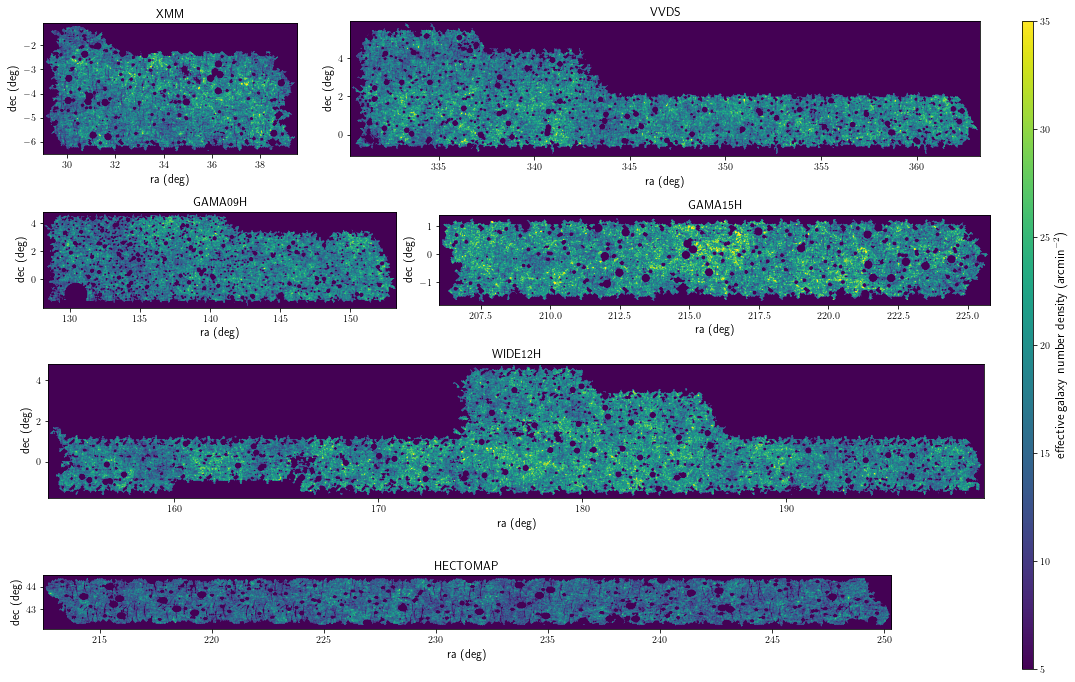

In [26]:
pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
lenList={}
imgList={}
cmax=0.
for fieldname in pltList:
    data=pyfits.getdata(os.path.join(outDir,'%s_wsMap.fits' %fieldname))
    print(fieldname)
    print(data.shape)
    lenList.update({fieldname:data.shape})
    imgList.update({fieldname:data})
    fmax=np.max(data)
    if fmax>cmax:
        cmax=fmax
        
plt.close()
#norm = mpl.colors.SymLogNorm(linthresh=0.4,vmin=5, vmax=cmax)
norm=mpl.colors.Normalize(vmin=5, vmax=35)

fig = plt.figure(figsize=(15,10))
ratio=int(1./(lenList['VVDS'][-1]/lenList['VVDS'][-2]/lenList['XMM'][-1]*lenList['XMM'][-2]+1.)*10.+0.5)
ax1 = plt.subplot2grid((8, 10), (0, 0), colspan=ratio,rowspan=2)
ax1.set_title('XMM',fontsize=12)
ax1.imshow(imgList['XMM'][0],origin='lower',extent=extList['XMM'],norm=norm)
ax1.set_xlabel('ra (deg)',fontsize=12)
ax1.set_ylabel('dec (deg)',fontsize=12)

ax2 = plt.subplot2grid((8, 10), (0, ratio), colspan=10-ratio,rowspan=2)
ax2.set_title('VVDS',fontsize=12)
ax2.imshow(imgList['VVDS'][0],origin='lower',extent=extList['VVDS'],norm=norm)
ax2.set_xlabel('ra (deg)',fontsize=12)
ax2.set_ylabel('dec (deg)',fontsize=12)

ratio=int(1./(lenList['GAMA15H'][-1]/lenList['GAMA15H'][-2]/lenList['GAMA09H'][-1]*lenList['GAMA09H'][-2]+1.)*10.+0.5)
ax3 = plt.subplot2grid((8, 10), (2, 0), colspan=ratio,rowspan=2)
ax3.set_title('GAMA09H',fontsize=12)
ax3.imshow(imgList['GAMA09H'][0],origin='lower',extent=extList['GAMA09H'],norm=norm)
ax3.set_xlabel('ra (deg)',fontsize=12)
ax3.set_ylabel('dec (deg)',fontsize=12)

ax4 = plt.subplot2grid((8, 10), (2, ratio), colspan=10-ratio,rowspan=2)
ax4.set_title('GAMA15H',fontsize=12)
ax4.imshow(imgList['GAMA15H'][0],origin='lower',extent=extList['GAMA15H'],norm=norm)
ax4.set_xlabel('ra (deg)',fontsize=12)
ax4.set_ylabel('dec (deg)',fontsize=12)

ax5 = plt.subplot2grid((8, 10), (4, 0), colspan=10,rowspan=2)
ax5.set_title('WIDE12H',fontsize=12)
ax5.imshow(imgList['WIDE12H'][0],origin='lower',extent=extList['WIDE12H'],norm=norm)
ax5.set_xlabel('ra (deg)',fontsize=12)
ax5.set_ylabel('dec (deg)',fontsize=12)

ax6 = plt.subplot2grid((8, 10), (6, 0), colspan=9,rowspan=2)
ax6.set_title('HECTOMAP',fontsize=12)
mm=ax6.imshow(imgList['HECTOMAP'][0],origin='lower',extent=extList['HECTOMAP'],norm=norm)
ax6.set_xlabel('ra (deg)',fontsize=12)
ax6.set_ylabel('dec (deg)',fontsize=12)

plt.tight_layout()
plt.subplots_adjust(bottom=0.05, right=0.92, top=0.95)
cax = plt.axes([0.95, 0.05, 0.01, 0.9])
plt.colorbar(mm,cax=cax)
cax.set_ylabel(r'effective galaxy number density (arcmin$^{-2}$)',fontsize=13)
fig.savefig(os.path.join(outDir,'wsMap.eps'))
fig.savefig(os.path.join(outDir,'wsMap.png'))

In [64]:
# Hex keys for the color scheme for shear catalog paper
plot_colors = {
    'GAMA09H' : '#d73027',
    'GAMA15H' : '#fc8d59',
    'HECTOMAP' : '#fee090',
    'VVDS' : '#000000',
    'WIDE12H' : '#91bfdb',
    'XMM' : '#4575b4'
    }

pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
xList={}
yList={}
cmax=0.
for fieldname in pltList:
    c=plot_colors[fieldname]
    datax=pyfits.getdata(os.path.join(outDir,'%s_fwhmMap.fits' %fieldname))
    datay=pyfits.getdata(os.path.join(outDir,'%s_wsMap.fits' %fieldname))
    mask=datay>0.
    datax=datax[mask]
    datay=datay[mask]
    print(fieldname,np.average(datay))
    xList.update({fieldname:datax})
    yList.update({fieldname:datay})

XMM 17.174090325882748
VVDS 17.839416785545072
GAMA09H 17.326281612868698
GAMA15H 19.31491066763506
WIDE12H 18.456154877078404
HECTOMAP 14.175227819967567


XMM 16.032042062296114
GAMA09H 17.09344843160423
WIDE12H 17.209680237895533
GAMA15H 17.399739768589836
VVDS 15.752361184125727
HECTOMAP 13.459030520246817


/home/xiangchong/work/ana/lsstsw/miniconda/envs/lsst-scipipe-cb4e2dc/lib/python3.7/site-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/home/xiangchong/work/ana/lsstsw/miniconda/envs/lsst-scipipe-cb4e2dc/lib/python3.7/site-packages/IPython/core/pylabtools.py:132: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


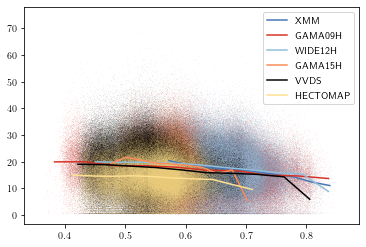

In [63]:
plt.close()
for fieldname in utilities.field_names:
    plt.scatter(xList[fieldname],yList[fieldname],s=0.005,c=plot_colors[fieldname],alpha=0.22)
    up,xx=np.histogram(xList[fieldname],bins=10,weights=yList[fieldname])
    down=np.histogram(xList[fieldname],bins=10)[0]
    xx=(xx[1:]+xx[:-1])/2.
    plt.errorbar(xx,up/down,ls='-',c=plot_colors[fieldname],label=fieldname)
    print(fieldname,np.average(up/down))
plt.legend()average

<ErrorbarContainer object of 3 artists>

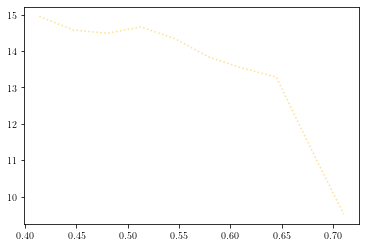

In [57]:
up,xx=np.histogram(xList[fieldname],bins=10,weights=yList[fieldname])
down=np.histogram(xList[fieldname],bins=10)[0]
xx=(xx[1:]+xx[:-1])/2.
plt.errorbar(xx,up/down,ls=':',c=plot_colors[fieldname])

In [62]:
np.average(up/down)

13.459030520246817

In [48]:
np.histogram(xList[fieldname],bins=10,weights=yList[fieldname])

(array([2.18474466e+04, 2.14437343e+05, 3.97902297e+05, 6.06439659e+05,
        7.89058939e+05, 8.55083481e+05, 3.42297477e+05, 9.29076412e+04,
        7.71462515e+03, 3.42727662e+02]),
 array([0.3973201 , 0.43030295, 0.46328581, 0.49626866, 0.52925152,
        0.56223437, 0.59521723, 0.62820009, 0.66118294, 0.6941658 ,
        0.72714865]))

{'XMM': array([0.71292504, 0.71178143, 0.68471938, ..., 0.76597241, 0.76420601,
        0.77211918]),
 'VVDS': array([0.45587387, 0.46165628, 0.44567009, ..., 0.52115381, 0.5195374 ,
        0.51886413]),
 'GAMA09H': array([0.68140526, 0.67427006, 0.6989466 , ..., 0.40556755, 0.73017782,
        0.49798685]),
 'GAMA15H': array([0.60751346, 0.60802108, 0.60777946, ..., 0.63934811, 0.62304338,
        0.53509253]),
 'WIDE12H': array([0.62108478, 0.60599364, 0.56159078, ..., 0.70640192, 0.68472024,
        0.68627805]),
 'HECTOMAP': array([0.47424982, 0.45327184, 0.46259646, ..., 0.55987543, 0.55581597,
        0.55179095])}